# RIGID: test single images

RIGID compares DINOv2 embeddings of an image and a slightly noisy copy of it.
**Real images score higher** (closer to 1.0). **AI-generated images score lower.**

The detector code lives in [rigid.py](rigid.py). This notebook only imports it.
The first run downloads DINOv2 ViT-L/14 (~1.2 GB, cached by `torch.hub`).

In [26]:
import matplotlib.pyplot as plt
from PIL import Image

from rigid import RIGIDDetector, calibrate_threshold

## Settings

- `IMAGE_PATH`: the image to test.
- `THRESHOLD`: the paper gives no fixed cutoff. Leave it as `None` to see only the score, or set one
  (for example from the calibration cell at the bottom) to get a real / AI-generated label.
- `N_NOISE`: number of noise draws averaged per image. The notebook uses 1; a few more give a steadier score.

In [43]:
IMAGE_PATH = "test_images/fake/Gemini_Generated_Image_9bgtmq9bgtmq9bgt.jpg"   # <-- set this

THRESHOLD = None        # e.g. 0.95; None = score only
N_NOISE = 8             # noise draws averaged per image
LAMB = 0.05             # noise intensity (paper default)
MODEL_NAME = "dinov2_vitl14"   # paper default; dinov2_vits14 / vitb14 are smaller and faster
DEVICE = None           # None = auto (cuda > mps > cpu)

## Load the detector (run once)

In [28]:
detector = RIGIDDetector(lamb=LAMB, model_name=MODEL_NAME, device=DEVICE, threshold=THRESHOLD)
print("Running on", detector.device)

Using cache found in /Users/michael/.cache/torch/hub/facebookresearch_dinov2_main


Running on mps


## Test the image

Change `IMAGE_PATH` above and re-run the settings cell and this cell. No need to reload the detector.

similarity = 0.9737 (± 0.0043)


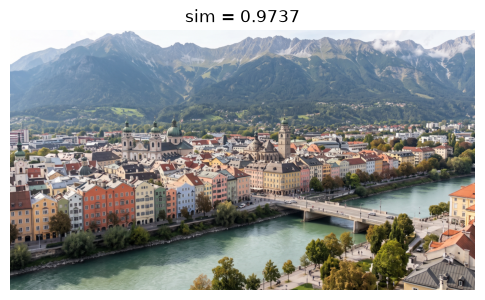

In [44]:
detector.threshold = THRESHOLD
result = detector.detect(IMAGE_PATH, n_noise=N_NOISE)
print(result)

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(IMAGE_PATH).convert("RGB"))
plt.title(f"sim = {result.similarity:.4f}" + (f"  |  {result.label}" if result.label else ""))
plt.axis("off")
plt.show()

## What DINOv2 actually sees

Top row: the original file, the **224×224 model input** after `detector.transform`
(resize → tensor → ImageNet normalization, shown un-normalized), the **noisy copy**
RIGID compares it with, and the noise itself (amplified so it is visible).

Bottom row: the centre `ZOOM`×`ZOOM` pixels of the original and of the model input,
drawn without smoothing so you can see individual pixels — e.g. how much a large
photo is averaged down, or how a tiny image is blurred up.

The noise draw is the same first draw `detect()` uses, so with `N_NOISE = 1` the
similarity printed here matches the result above.

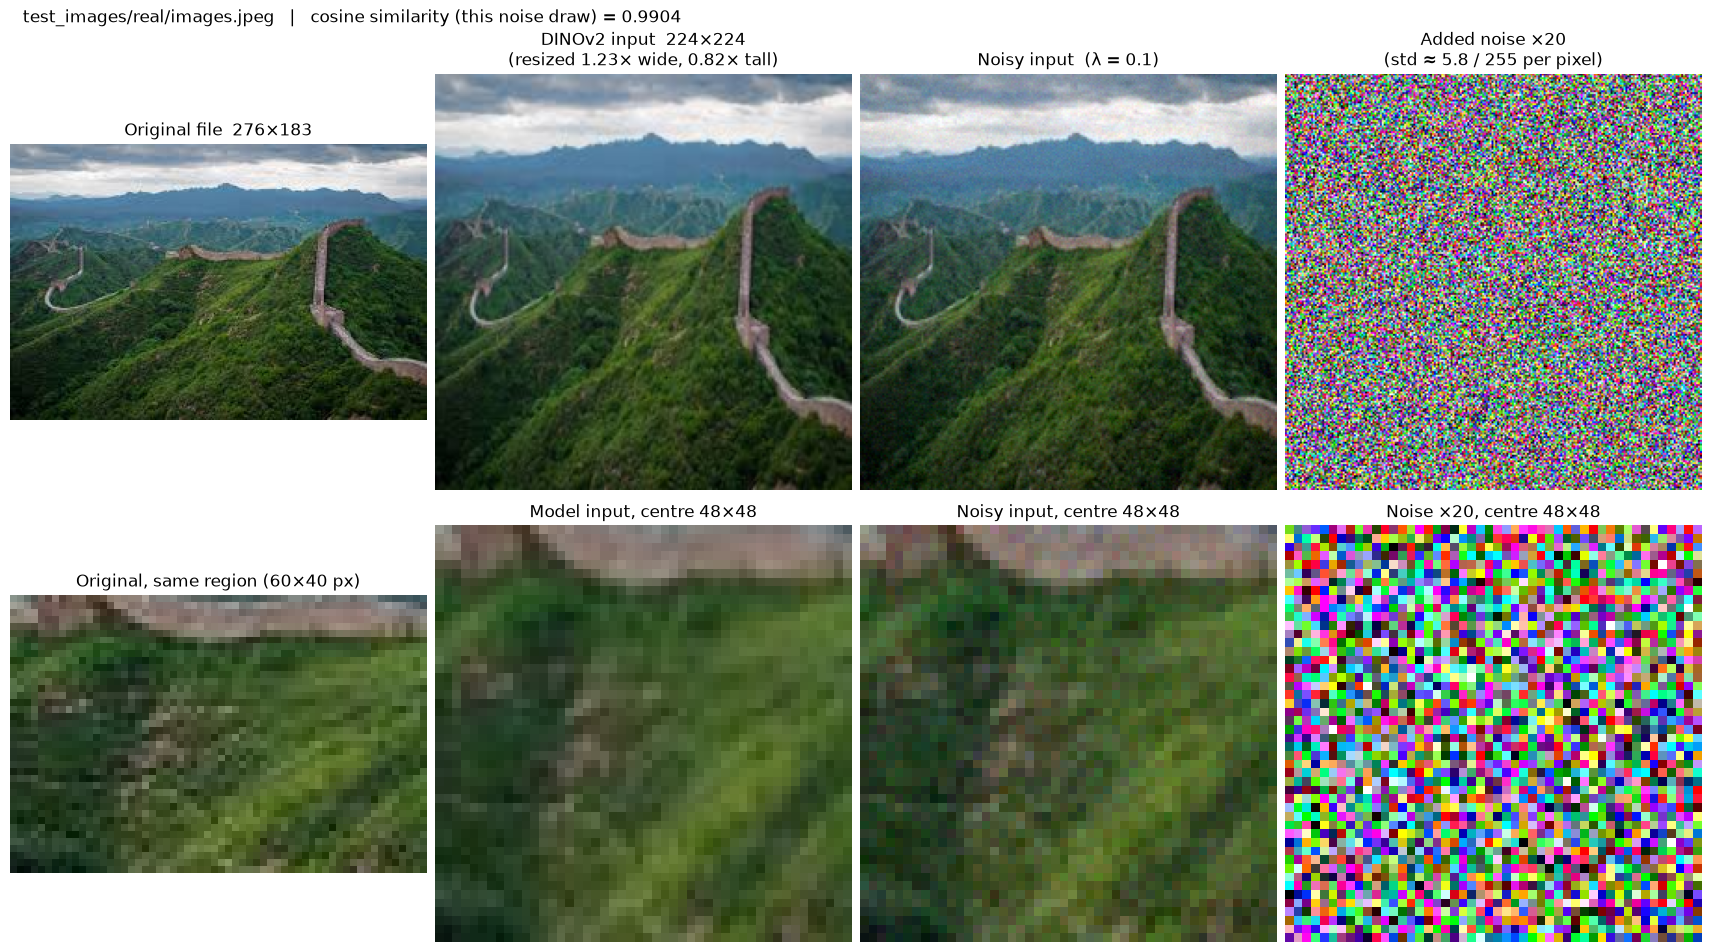

In [39]:
import numpy as np
import torch
import torch.nn.functional as F
from rigid import DEFAULT_MEAN, DEFAULT_STD

NOISE_AMPLIFY = 20   # scale the noise so it is visible
ZOOM = 48            # side of the centre patch shown in the bottom row (model-input pixels)

orig = Image.open(IMAGE_PATH).convert("RGB")
x = detector.preprocess(orig)                                   # (1, 3, 224, 224), normalized
gen = torch.Generator().manual_seed(detector.seed) if detector.seed is not None else None
noise = torch.randn(x.shape, generator=gen).to(x.device)        # same draw as detect()
x_noisy = x + noise * detector.lamb

mean = torch.tensor(DEFAULT_MEAN, device=x.device).view(3, 1, 1)
std = torch.tensor(DEFAULT_STD, device=x.device).view(3, 1, 1)
def to_img(t):
    """Undo normalization -> HxWx3 array in [0, 1] for display."""
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

inp, inp_noisy = to_img(x[0]), to_img(x_noisy[0])
noise_px = (noise[0] * detector.lamb * std).permute(1, 2, 0).cpu().numpy()   # in [0,1] pixel units

with torch.no_grad():
    sim = F.cosine_similarity(detector.model(x), detector.model(x_noisy), dim=-1).item()

W, H = orig.size
side = x.shape[-1]
fig, ax = plt.subplots(2, 4, figsize=(17, 9.5), layout="constrained")
ax[0, 0].imshow(orig);       ax[0, 0].set_title(f"Original file  {W}×{H}")
ax[0, 1].imshow(inp);        ax[0, 1].set_title(f"DINOv2 input  {side}×{side}\n(resized {W/side:.2f}× wide, {H/side:.2f}× tall)")
ax[0, 2].imshow(inp_noisy);  ax[0, 2].set_title(f"Noisy input  (λ = {detector.lamb})")
ax[0, 3].imshow((0.5 + noise_px * NOISE_AMPLIFY).clip(0, 1))
ax[0, 3].set_title(f"Added noise ×{NOISE_AMPLIFY}\n(std ≈ {noise_px.std() * 255:.1f} / 255 per pixel)")

# Bottom row: centre patches, nearest-neighbour so pixels stay visible
c, h = side // 2, ZOOM // 2
cx, cy, hw, hh = W // 2, H // 2, round(h * W / side), round(h * H / side)
ax[1, 0].imshow(orig.crop((cx - hw, cy - hh, cx + hw, cy + hh)), interpolation="nearest")
ax[1, 0].set_title(f"Original, same region ({2*hw}×{2*hh} px)")
ax[1, 1].imshow(inp[c-h:c+h, c-h:c+h], interpolation="nearest");        ax[1, 1].set_title(f"Model input, centre {ZOOM}×{ZOOM}")
ax[1, 2].imshow(inp_noisy[c-h:c+h, c-h:c+h], interpolation="nearest");  ax[1, 2].set_title(f"Noisy input, centre {ZOOM}×{ZOOM}")
ax[1, 3].imshow((0.5 + noise_px[c-h:c+h, c-h:c+h] * NOISE_AMPLIFY).clip(0, 1), interpolation="nearest")
ax[1, 3].set_title(f"Noise ×{NOISE_AMPLIFY}, centre {ZOOM}×{ZOOM}")
for a in ax.flat:
    a.axis("off")
fig.suptitle(f"{IMAGE_PATH}   |   cosine similarity (this noise draw) = {sim:.4f}", x=0.01, ha="left")
plt.show()

## Optional: pick a threshold from your own images

List a few images you know are real and a few you know are AI-generated, ideally similar to what you
plan to test. This finds the cutoff that best separates them. Copy the printed value into `THRESHOLD`.

In [40]:
REAL_IMAGES = ["test_images/real/image copy.png", "test_images/real/image.png", "test_images/real/images.jpeg", "test_images/real/IMG_1255.JPG"]   # e.g. ["photos/cat.jpg", "photos/street.png"]
FAKE_IMAGES = ["test_images/fake/Gemini_Generated_Image_6b0c6a6b0c6a6b0c.jpg", "test_images/fake/Gemini_Generated_Image_9bgtmq9bgtmq9bgt.jpg"]   # e.g. ["generated/sd_001.png", "generated/mj_002.png"]

if REAL_IMAGES and FAKE_IMAGES:
    real_scores = [detector.score(p, n_noise=N_NOISE)[0] for p in REAL_IMAGES]
    fake_scores = [detector.score(p, n_noise=N_NOISE)[0] for p in FAKE_IMAGES]
    for p, s in zip(REAL_IMAGES, real_scores): print(f"real  {s:.4f}  {p}")
    for p, s in zip(FAKE_IMAGES, fake_scores): print(f"fake  {s:.4f}  {p}")
    print("Suggested THRESHOLD =", round(calibrate_threshold(real_scores, fake_scores), 4))
else:
    print("Fill in REAL_IMAGES and FAKE_IMAGES to calibrate.")

real  0.9380  test_images/real/image copy.png
real  0.9208  test_images/real/image.png
real  0.9907  test_images/real/images.jpeg
real  0.9654  test_images/real/IMG_1255.JPG
fake  0.9893  test_images/fake/Gemini_Generated_Image_6b0c6a6b0c6a6b0c.jpg
fake  0.9737  test_images/fake/Gemini_Generated_Image_9bgtmq9bgtmq9bgt.jpg
Suggested THRESHOLD = 0.9907
